# ModelAtlas: exploring the model graph

A short, read-only tour of model families, licenses and training datasets.
Run all cells from the repository root with the Neo4j database and API running.
Install `requirements-notebook.txt` with **Python 3.12 or newer**.

The saved run uses the full graph, not the small test fixture. Its dataset-card
loader is PR #5 at commit `4a8966dddcfe478805a3fdddde8e8f7cef9922f6`.
The two downloaded data revisions are shown below. This draft should be merged
after #5, #7 and #8; it does not merge those PRs itself.

## 1. Setup

The password comes from `.env` or the environment and is never displayed.
Defaults are `bolt://localhost:7687` and `http://127.0.0.1/api`.
Set `NEO4J_NOTEBOOK_URI` and `MODELATLAS_API_URL` to use other local ports.
Reads use READ sessions, a 10-second query timeout and bounded result lists.

In [1]:
from time import perf_counter

started = perf_counter()

import json
import os
import platform
from pathlib import Path
from urllib.parse import quote
from typing import Any

import matplotlib
import matplotlib.pyplot as plt
import networkx as nx
import pandas as pd
import requests
from dotenv import dotenv_values
from IPython.display import display
from neo4j import READ_ACCESS, GraphDatabase, Query

get_ipython().run_line_magic("matplotlib", "inline")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

root = Path.cwd()
config = dotenv_values(root / ".env")
password = os.getenv("NEO4J_PASSWORD") or config.get("NEO4J_PASSWORD")
if not password:
    raise RuntimeError("Set NEO4J_PASSWORD in .env before running this notebook.")
uri = os.getenv("NEO4J_NOTEBOOK_URI") or config.get("NEO4J_NOTEBOOK_URI", "bolt://localhost:7687")
user = os.getenv("NEO4J_USER") or config.get("NEO4J_USER", "neo4j")
database = os.getenv("NEO4J_DATABASE") or config.get("NEO4J_DATABASE", "neo4j")
api_url = os.getenv("MODELATLAS_API_URL") or config.get("MODELATLAS_API_URL", "http://127.0.0.1/api")
driver = GraphDatabase.driver(uri, auth=(user, password), connection_timeout=10)
driver.verify_connectivity()
http = requests.Session()
http.trust_env = False  # Local requests must not go through a system HTTP proxy.


def read(cypher: str, **params: Any) -> list[dict[str, Any]]:
    """Fetch a bounded query result through a read-only session."""
    with driver.session(database=database, default_access_mode=READ_ACCESS) as session:
        return session.run(Query(cypher, timeout=10), params).data()


def api(path: str, **params: Any) -> dict[str, Any]:
    """Call the running API, failing clearly on an unsuccessful response."""
    response = http.get(f"{api_url.rstrip('/')}/{path.lstrip('/')}", params=params, timeout=15)
    response.raise_for_status()
    return response.json()


assert api("/health")["status"] == "ok"
data_dir = Path(os.getenv("MODELATLAS_DATA_DIR") or config.get("MODELATLAS_DATA_DIR", root / "data"))
provenance = []
for source in ("model_cards", "dataset_cards"):
    manifest = data_dir / "raw" / source / "manifest.json"
    revision = (
        json.loads(manifest.read_text(encoding="utf-8"))["commit"] if manifest.exists() else "not available locally"
    )
    provenance.append({"source": source, "dump commit": revision})
display(pd.DataFrame(provenance))
print(f"Python {platform.python_version()} | matplotlib {matplotlib.__version__} | networkx {nx.__version__}")


,source,dump commit
0,model_cards,99b6ce9d9d47f796700745ed9630556c91c00439
1,dataset_cards,a20ebd23b0e74614bd0458f264e46b31df52718a


Python 3.12.14 | matplotlib 3.11.2 | networkx 3.7


## 2. Graph overview

These are counts from the live database. `Unlisted` is an extra label on
a `Model`, so label counts overlap and should not be added as distinct entities.
Relationships include the dataset-card links when the second source is loaded.

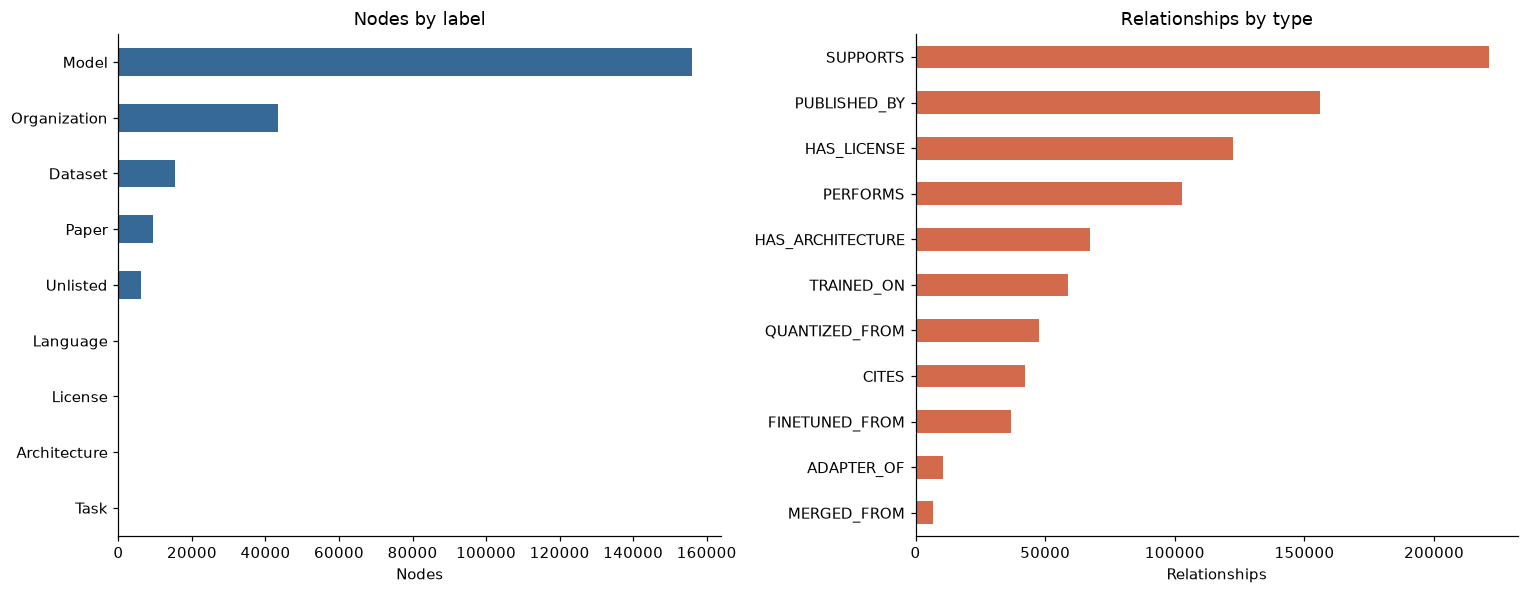

API and database agree: 156,071 Model nodes.


In [2]:
node_counts = pd.DataFrame(
    read(
        "MATCH (n) UNWIND labels(n) AS label RETURN label, count(*) AS nodes "
        "ORDER BY nodes DESC, label LIMIT $limit",
        limit=50,
    )
)
relation_counts = pd.DataFrame(
    read(
        "MATCH ()-[r]->() RETURN type(r) AS relation, count(*) AS links " "ORDER BY links DESC, relation LIMIT $limit",
        limit=50,
    )
)
assert not node_counts.empty and not relation_counts.empty, "Load the full graph before running the demo."
model_count = int(node_counts.set_index("label").loc["Model", "nodes"])
assert api("/stats")["models"] == model_count, "The API and driver must point to the same graph."

fig, axes = plt.subplots(1, 2, figsize=(14, 5.5))
node_counts.iloc[::-1].plot.barh(x="label", y="nodes", ax=axes[0], color="#376996", legend=False)
relation_counts.iloc[::-1].plot.barh(x="relation", y="links", ax=axes[1], color="#d46a4c", legend=False)
axes[0].set(title="Nodes by label", xlabel="Nodes", ylabel="")
axes[1].set(title="Relationships by type", xlabel="Relationships", ylabel="")
fig.tight_layout()
plt.show()
print(f"API and database agree: {model_count:,} Model nodes.")


In [3]:
driver.close()
http.close()
elapsed = perf_counter() - started
print(f"Analysis completed in {elapsed:.1f} seconds; connections closed.")
assert elapsed < 120, "The demo should finish in less than two minutes on the prepared stack."


Analysis completed in 12.8 seconds; connections closed.
